# DINOv2 hold embeddings

Turns every labeled hold into a 384-number appearance embedding: a summary of what the hold looks like (shape, texture, size in the crop, color), computed by DINOv2 model. We then pass these into the next-hold transformer later on.

1. Cuts a square crop around each hold from its position's clean reference frame (`hold-maps/posX_frame.png`), with some wall around it for context.
2. Makes `N_VARIANTS` versions of each crop: one clean with the rest slightly augmented. During training a random version is used each time so we don't overfit.
3. Runs all crops through DINOv2 and keeps two kinds of embedding per crop to later experiment with:
   - `cls`: DINOv2's summary token for the whole crop (hold plus surrounding wall).
   - `hold`: the average of DINOv2's patch features inside the hold's outline only, so the wall around it barely counts.

## Cell 1: Setup

- `N_VARIANTS`: crop versions per hold
- `CONTEXT`: how much wall to include
- `MIN_CROP_PX`: smallest crop side in video pixels
- `IMG`: size the crops are resized to for DINOv2
- No hue changes in the variants

In [ ]:
import os, json
import cv2
import numpy as np
import pandas as pd
import torch
from google.colab import drive

drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/ECS-174-Project'
MAP_DIR = f'{BASE}/hold-maps'
EMB_DIR = f'{BASE}/embeddings'
os.makedirs(f'{EMB_DIR}/checks', exist_ok=True)

N_VARIANTS = 5          
CONTEXT = 2.0           # crop size = CONTEXT x the hold's larger dimension
MIN_CROP_PX = 64        # smallest crop size
IMG = 224               # DINOv2 input size
SHIFT = 0.10            # jitter: shift up to 10% of the crop side
ZOOM = 0.15             # jitter: crop size
BRIGHT = 0.15           # jitter: brightness and contrast
SEED = 0

Mounted at /content/drive


## Cell 2: Load the hold maps

Reads `holds.csv`, `hold_polygons.json` and each position's reference frame.

In [ ]:
holds = pd.read_csv(f'{MAP_DIR}/holds.csv')
holds['color'] = holds['color'].fillna('')
polygons = json.load(open(f'{MAP_DIR}/hold_polygons.json'))

frames = {}
for pos in sorted(holds.position_id.unique()):
    f = cv2.imread(f'{MAP_DIR}/{pos}_frame.png')
    if f is None:
        print(f'MISSING {pos}_frame.png: holds are skipped')
        continue
    frames[pos] = cv2.cvtColor(f, cv2.COLOR_BGR2RGB)        # convert to RGB for DINOv2

# print results
index = (holds[holds.position_id.isin(frames)]
         .sort_values(['position_id', 'hold_id']).reset_index(drop=True))
index = index[['position_id', 'hold_id', 'cls', 'color', 'center_x', 'center_y', 'width', 'height']]
print(f'{len(index)} holds at {index.position_id.nunique()} positions')
print(index.cls.value_counts().to_string())

4309 holds at 38 positions
cls
hold      4092
down       120
volume      97


## Cell 3: Make the crops

For each hold and each variant: pick a square around the hold's center, resizes it to 224 × 224, and draws the hold's outline into a matching 224 × 224 mask. The mask is then shrunk to the 16 × 16 patch grid, giving each DINOv2 patch a weight: how much of that patch the hold covers.

In [ ]:
rng = np.random.default_rng(SEED)
GRID = IMG // 14
PAD = 1200                                                # mirror padding, so crops dont leave img

padded = {pos: cv2.copyMakeBorder(f, PAD, PAD, PAD, PAD, cv2.BORDER_REFLECT_101) for pos, f in frames.items()}

def crop_and_mask(pos, hold_id, cx, cy, w, h, variant):
    '''One square crop (IMG x IMG, RGB uint8) and its patch weights (GRID x GRID, sum 1).'''
    side = max(CONTEXT * max(w, h), MIN_CROP_PX)
    if variant > 0:                                       # create jittered versions
        side *= 1 + rng.uniform(-ZOOM, ZOOM)
        cx += rng.uniform(-SHIFT, SHIFT) * side
        cy += rng.uniform(-SHIFT, SHIFT) * side
    x0, y0 = cx - side / 2, cy - side / 2
    s = IMG / side                                        # video pixels to crop pixels
    M = np.float32([[s, 0, -(x0 + PAD) * s], [0, s, -(y0 + PAD) * s]])
    crop = cv2.warpAffine(padded[pos], M, (IMG, IMG), flags=cv2.INTER_AREA if s < 1 else cv2.INTER_LINEAR)
    if variant > 0:
        a = 1 + rng.uniform(-BRIGHT, BRIGHT)              # contrast
        b = 255 * rng.uniform(-BRIGHT, BRIGHT) / 2        # brightness
        crop = np.clip(crop.astype(np.float32) * a + b, 0, 255).astype(np.uint8)

    mask = np.zeros((IMG, IMG), np.uint8)
    for part in polygons[pos][str(hold_id)]:
        pts = (np.array(part, np.float32) - [x0, y0]) * s
        cv2.fillPoly(mask, [np.round(pts).astype(np.int32)], 1)
    weights = cv2.resize(mask.astype(np.float32), (GRID, GRID), interpolation=cv2.INTER_AREA)
    tiny = weights.sum() < 0.5                            # under half a patch covered
    if tiny:                                              # fall back to the patches at the crop center
        weights = np.zeros((GRID, GRID), np.float32)
        weights[GRID // 2 - 1:GRID // 2 + 1, GRID // 2 - 1:GRID // 2 + 1] = 1
    return crop, weights / weights.sum(), tiny

n = len(index)
crops = np.zeros((n, N_VARIANTS, IMG, IMG, 3), np.uint8)
weights = np.zeros((n, N_VARIANTS, GRID * GRID), np.float32)
n_tiny = 0
for i, r in enumerate(index.itertuples(index=False)):
    for v in range(N_VARIANTS):
        c, wt, tiny = crop_and_mask(r.position_id, r.hold_id, r.center_x, r.center_y, r.width, r.height, v)
        crops[i, v], weights[i, v] = c, wt.ravel()
        n_tiny += tiny and v == 0
# return how many holds are little (if high maybe we change some stuff)
print(f'{n * N_VARIANTS} crops ({n} holds x {N_VARIANTS} variants); holds with tiny masks: {n_tiny}')

21545 crops (4309 holds x 5 variants); holds with tiny masks: 1


## Cell 4: Print sample crops 

Check if we need to change anything before running

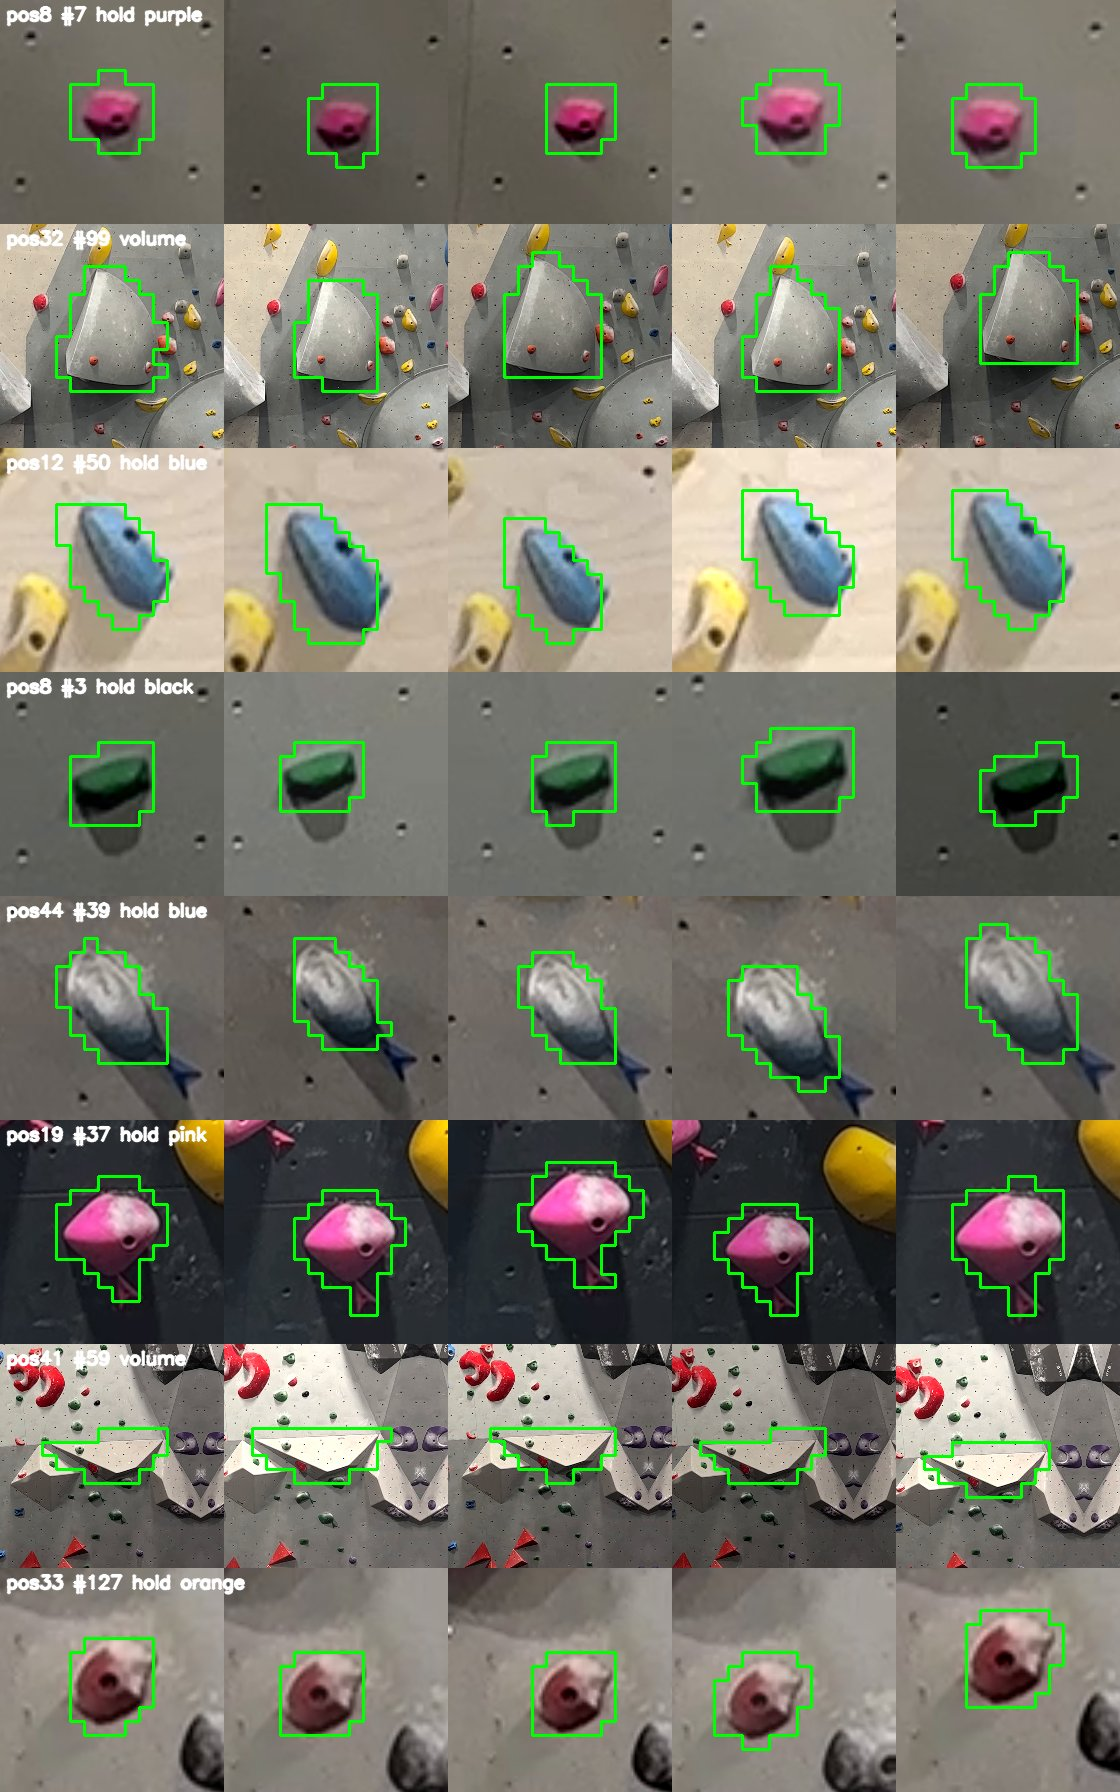

In [ ]:
from IPython.display import Image, display

def outlined(i, v):
    img = crops[i, v].copy()
    m = (weights[i, v].reshape(GRID, GRID) > 0).astype(np.uint8)
    m = cv2.resize(m, (IMG, IMG), interpolation=cv2.INTER_NEAREST)
    contours, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(img, contours, -1, (0, 255, 0), 2)      # patch-level outline of the hold
    return img

pick = np.random.default_rng(1).choice(n, size=min(8, n), replace=False)
rows = []
for i in pick:
    r = index.iloc[i]
    row = np.hstack([outlined(i, v) for v in range(N_VARIANTS)])
    cv2.putText(row, f'{r.position_id} #{r.hold_id} {r.cls} {r.color}', (6, 20),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2, cv2.LINE_AA)
    rows.append(row)
grid = cv2.cvtColor(np.vstack(rows), cv2.COLOR_RGB2BGR)
cv2.imwrite(f'{EMB_DIR}/checks/sample_crops.jpg', grid, [cv2.IMWRITE_JPEG_QUALITY, 85])
display(Image(filename=f'{EMB_DIR}/checks/sample_crops.jpg', width=900))

## Cell 5: Run DINOv2

Download DINOv2 and put it in evaluation mode. Each crop is normalized with the ImageNet mean and standard deviation and run in batches of 128.

In [ ]:
DEVICE = 'cuda'
print('GPU:', torch.cuda.get_device_name(0))

model = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14').to(DEVICE).eval()
MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

# put it eval mode no gradient updates
@torch.no_grad()
def embed_batch(imgs, wts):
    '''imgs: (B, IMG, IMG, 3) uint8 RGB; wts: (B, GRID*GRID) patch weights -> (cls, hold), each (B, 384).'''
    x = torch.from_numpy(imgs).pin_memory().to(DEVICE, non_blocking=True)
    x = (x.permute(0, 3, 1, 2).float() / 255 - MEAN) / STD
    with torch.autocast('cuda', dtype=torch.float16):         # half precision fine to use here 
        out = model.forward_features(x)
    cls = out['x_norm_clstoken'].float()                       # (B, 384)
    patches = out['x_norm_patchtokens'].float()                # (B, GRID*GRID, 384)
    w = torch.from_numpy(wts).to(DEVICE).unsqueeze(-1)         # (B, GRID*GRID, 1), sums to 1 per crop
    hold = (patches * w).sum(dim=1)                            # weighted average over the hold's patches
    return cls.cpu().numpy(), hold.cpu().numpy()

flat_crops = crops.reshape(-1, IMG, IMG, 3)
flat_w = weights.reshape(-1, GRID * GRID)
BATCH = 256

def run_all(mirror):
    '''Embeds every crop; mirror=True flips each crop and its patch weights left to right first.'''
    cls_all = np.zeros((len(flat_crops), 384), np.float32)
    hold_all = np.zeros((len(flat_crops), 384), np.float32)
    for start in range(0, len(flat_crops), BATCH):
        sl = slice(start, start + BATCH)
        imgs, wts = flat_crops[sl], flat_w[sl]
        if mirror:
            imgs = np.ascontiguousarray(imgs[:, :, ::-1])                       # flip image width
            wts = np.ascontiguousarray(wts.reshape(-1, GRID, GRID)[:, :, ::-1]  # flip patch columns
                                       .reshape(-1, GRID * GRID))
        cls_all[sl], hold_all[sl] = embed_batch(imgs, wts)
        if (start // BATCH) % 10 == 0:
            print(f'{"mirrored " if mirror else ""}{min(start + BATCH, len(flat_crops))}/{len(flat_crops)} crops',
                  flush=True)
    return cls_all.reshape(n, N_VARIANTS, 384), hold_all.reshape(n, N_VARIANTS, 384)

emb_cls, emb_hold = run_all(mirror=False)
emb_cls_flip, emb_hold_flip = run_all(mirror=True)
for a in (emb_cls, emb_hold, emb_cls_flip, emb_hold_flip):
    assert np.isfinite(a).all(), 'NaN/inf in embeddings'
print('cls', emb_cls.shape, ' hold', emb_hold.shape, ' cls_flip', emb_cls_flip.shape, ' hold_flip', emb_hold_flip.shape)

GPU: Tesla T4
Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 399MB/s]


256/21545 crops
2816/21545 crops
5376/21545 crops
7936/21545 crops
10496/21545 crops
13056/21545 crops
15616/21545 crops
18176/21545 crops
20736/21545 crops
mirrored 256/21545 crops
mirrored 2816/21545 crops
mirrored 5376/21545 crops
mirrored 7936/21545 crops
mirrored 10496/21545 crops
mirrored 13056/21545 crops
mirrored 15616/21545 crops
mirrored 18176/21545 crops
mirrored 20736/21545 crops
cls (4309, 5, 384)  hold (4309, 5, 384)  cls_flip (4309, 5, 384)  hold_flip (4309, 5, 384)


## Cell 6: Save

- `embeddings/hold_embeddings.npz`: arrays `cls` and `hold` (holds × variants × 384, float16)
- `embeddings/hold_index.csv`: the same order as readable rows (position, hold ID, class, color).

In [ ]:
path = f'{EMB_DIR}/hold_embeddings.npz'
np.savez_compressed(path, cls=emb_cls.astype(np.float16), hold=emb_hold.astype(np.float16),
                    cls_flip=emb_cls_flip.astype(np.float16), hold_flip=emb_hold_flip.astype(np.float16),
                    position_id=index.position_id.to_numpy(str), hold_id=index.hold_id.to_numpy(int),
                    settings=json.dumps({'model': 'dinov2_vits14', 'n_variants': N_VARIANTS, 'context': CONTEXT,
                                         'min_crop_px': MIN_CROP_PX, 'img': IMG, 'shift': SHIFT,
                                         'zoom': ZOOM, 'bright': BRIGHT, 'seed': SEED}))
index.to_csv(f'{EMB_DIR}/hold_index.csv', index=False)

check = np.load(path)
for k in ('cls', 'hold', 'cls_flip', 'hold_flip'):
    assert check[k].shape == (n, N_VARIANTS, 384), k
assert (check['hold_id'] == index.hold_id.to_numpy()).all()
print(f'saved {path} ({os.path.getsize(path) / 1e6:.1f} MB), reload OK')

saved /content/drive/MyDrive/ECS-174-Project/embeddings/hold_embeddings.npz (61.1 MB), reload OK
